In [ ]:
# N_comp_comparison.xlsx created from running Walen Analysis.ipynb, Four-spacecraft timing normals.ipynb, and MDD-MDDB.ipynb

In [1]:
import numpy as np
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import re
import pyspedas
# ============================================================
# SETTINGS
# ============================================================

t_start = pd.Timestamp("2020-06-17 21:00:00")
t_end   = pd.Timestamp("2020-06-18 01:30:00")

trange = ['2020-06-17/21:00:00','2020-06-18/01:30:00']
probe = '2'
# Change if your density column has a different name
density_col = "ni"

# Smoothing used only to help identify the KH-scale maxima
smooth_seconds = 45

# Read in and parse N vectors from four-spacecraft timing normal, cross product, and MDD

In [2]:
# ============================================================
# 1. READ NORMAL-COMPARISON SPREADSHEET
# ============================================================

#file_path = "/Users/christylentz/iCloud/LASP-MacL4326/MMS/KH_project/N_comp_comparison.xlsx"
file_path = "/Users/christylentz/iCloud/LASP-MacL4326/MMS/KH_project/N_comp_comparison copy.xlsx"


N_results = pd.read_excel(
    file_path,
    sheet_name="Sheet1"
)

In [3]:
# ============================================================
# 2. PARSE VECTOR COLUMNS
# ============================================================

def parse_vector(value):
    """
    Convert spreadsheet strings such as

        '[0.09, 0.86, -0.50]'

    or

        '[-0.139  -0.827  0.545]'

    into a numpy array:

        array([0.09, 0.86, -0.50])

    Also handles malformed brackets, such as Event 8 N_MDD.
    """

    if isinstance(value, np.ndarray):
        return value.astype(float)

    # Extract every valid floating-point number
    numbers = re.findall(
        r"[-+]?(?:\d*\.\d+|\d+\.?)(?:[eE][-+]?\d+)?",
        str(value)
    )

    vector = np.array(
        [float(x) for x in numbers],
        dtype=float
    )

    if len(vector) != 3:
        raise ValueError(
            f"Expected 3 components but found "
            f"{len(vector)} in:\n{value}"
        )

    return vector


for col in [
    "N_cross",
    "N_timing",
    "N_MDD"
]:

    N_results[col] = (
        N_results[col]
        .apply(parse_vector)
    )

In [4]:
# ============================================================
# 3. NORMALIZE ALL VECTORS
# ============================================================

def normalize(v):

    v = np.asarray(
        v,
        dtype=float
    )

    return v / np.linalg.norm(v)


for col in [
    "N_cross",
    "N_timing",
    "N_MDD"
]:

    N_results[col] = (
        N_results[col]
        .apply(normalize)
    )

In [5]:
# ============================================================
# 4. RESOLVE +/- AMBIGUITY USING TIMING NORMAL
# ============================================================

def orient_to_timing(
    vector,
    timing
):

    vector = normalize(vector)
    timing = normalize(timing)

    if np.dot(
        vector,
        timing
    ) < 0:

        vector = -vector

    return vector


N_results["N_cross_signed"] = [
    orient_to_timing(
        row["N_cross"],
        row["N_timing"]
    )
    for _, row in N_results.iterrows()
]


N_results["N_MDD_signed"] = [
    orient_to_timing(
        row["N_MDD"],
        row["N_timing"]
    )
    for _, row in N_results.iterrows()
]

In [6]:
# ============================================================
# 5. EXPAND NORMALS INTO COMPONENT COLUMNS
# ============================================================

methods = {
    "cross": "N_cross_signed",
    "timing": "N_timing",
    "mdd": "N_MDD_signed"
}


for method, column in methods.items():

    N_results[
        f"Nx_{method}"
    ] = N_results[column].apply(
        lambda x: x[0]
    )

    N_results[
        f"Ny_{method}"
    ] = N_results[column].apply(
        lambda x: x[1]
    )

    N_results[
        f"Nz_{method}"
    ] = N_results[column].apply(
        lambda x: x[2]
    )

In [7]:
# ============================================================
# 6. ANGULAR DIFFERENCES
# ============================================================

def angle_deg(a, b):

    a = normalize(a)
    b = normalize(b)

    return np.degrees(
        np.arccos(
            np.clip(
                np.dot(a, b),
                -1,
                1
            )
        )
    )


N_results["angle_cross_timing"] = [
    angle_deg(
        row["N_cross_signed"],
        row["N_timing"]
    )
    for _, row in N_results.iterrows()
]


N_results["angle_mdd_timing"] = [
    angle_deg(
        row["N_MDD_signed"],
        row["N_timing"]
    )
    for _, row in N_results.iterrows()
]

In [8]:
# ============================================================
# 7. RESULTS TABLE
# ============================================================

display_columns = [

    "event num",

    "Nx_cross",
    "Ny_cross",
    "Nz_cross",

    "Nx_timing",
    "Ny_timing",
    "Nz_timing",

    "Nx_mdd",
    "Ny_mdd",
    "Nz_mdd",

    "angle_cross_timing",
    "angle_mdd_timing"
]


print(
    N_results[
        display_columns
    ].round(3).to_string(
        index=False
    )
)

 event num  Nx_cross  Ny_cross  Nz_cross  Nx_timing  Ny_timing  Nz_timing  Nx_mdd  Ny_mdd  Nz_mdd  angle_cross_timing  angle_mdd_timing
         1    -0.091    -0.861     0.501     -0.011     -0.889      0.457  -0.139  -0.827   0.545               5.430             9.601
         2     0.247    -0.966     0.075     -0.462     -0.841     -0.282  -0.034  -0.971   0.235              47.368            40.000
         3    -0.414     0.908     0.069      0.369      0.883     -0.289  -0.011   0.998  -0.056              51.000            26.593
         4    -0.641    -0.064     0.765     -0.685      0.030      0.728  -0.618   0.068   0.783               6.328             5.425
         5    -0.659     0.744     0.110     -0.423      0.903      0.079  -0.598   0.767   0.232              16.483            15.475
         6    -0.809     0.195     0.554     -0.860      0.270      0.433  -0.835   0.209   0.509               8.663             5.772
         7    -0.385     0.874     0.297     -0.

# Create Events dataframe

In [9]:

events = pd.DataFrame({

    "event": np.arange(1, 16),

    "start": pd.to_datetime([
        "2020-06-17 21:16:55.000",
        "2020-06-17 21:24:36.000",
        "2020-06-17 21:40:51.400",
        "2020-06-17 22:18:18.200",
        "2020-06-17 22:43:34.000",
        "2020-06-17 22:46:25.250",
        "2020-06-17 23:03:50.000",
        "2020-06-17 23:10:43.000",
        "2020-06-17 23:17:17.299",
        "2020-06-17 23:34:55.400",
        "2020-06-17 23:42:47.000",
        "2020-06-17 23:49:26.400",
        "2020-06-17 23:57:57.599",
        "2020-06-18 00:09:41.000",
        "2020-06-18 00:22:09.000"
    ]),

    "end": pd.to_datetime([
        "2020-06-17 21:17:07.000",
        "2020-06-17 21:25:20.000",
        "2020-06-17 21:41:20.799",
        "2020-06-17 22:18:31.000",
        "2020-06-17 22:44:03.599",
        "2020-06-17 22:46:38.500",
        "2020-06-17 23:03:58.000",
        "2020-06-17 23:10:52.000",
        "2020-06-17 23:17:28.000",
        "2020-06-17 23:35:17.500",
        "2020-06-17 23:42:59.000",
        "2020-06-17 23:49:46.350",
        "2020-06-17 23:58:25.000",
        "2020-06-18 00:10:05.000",
        "2020-06-18 00:22:35.599"
    ]),

    "type": [
        "Leading",
        "Trailing",
        "Trailing",
        "Leading",
        "Trailing",
        "Leading",
        "Trailing",
        "Undefined",
        "Leading",
        "Leading",
        "Trailing",
        "Leading",
        "Trailing",
        "Undefined",
        "Trailing"
    ]
})


# ============================================================
# 2. EVENT MIDPOINTS
# ============================================================

events["mid"] = (
    events["start"]
    + (events["end"] - events["start"]) / 2
)

# Load data and identify KH peaks

In [10]:
fpi_i_files = pyspedas.projects.mms.fpi(
    probe=probe,
    trange=trange,
    datatype="dis-moms",
    data_rate="brst",
    level="l2"
)

02-Oct-26 12:15:00: Loading files for group: probe: 2, drate: brst, level: l2, datatype: dis-moms, after sorting and filtering:
02-Oct-26 12:15:00: /Users/christylentz/MMS_data/mms/mms2/fpi/brst/l2/dis-moms/2020/06/17/mms2_fpi_brst_l2_dis-moms_20200617205913_v3.4.0.cdf
02-Oct-26 12:15:00: /Users/christylentz/MMS_data/mms/mms2/fpi/brst/l2/dis-moms/2020/06/17/mms2_fpi_brst_l2_dis-moms_20200617210143_v3.4.0.cdf
02-Oct-26 12:15:00: /Users/christylentz/MMS_data/mms/mms2/fpi/brst/l2/dis-moms/2020/06/17/mms2_fpi_brst_l2_dis-moms_20200617210413_v3.4.0.cdf
02-Oct-26 12:15:00: /Users/christylentz/MMS_data/mms/mms2/fpi/brst/l2/dis-moms/2020/06/17/mms2_fpi_brst_l2_dis-moms_20200617210643_v3.4.0.cdf
02-Oct-26 12:15:00: /Users/christylentz/MMS_data/mms/mms2/fpi/brst/l2/dis-moms/2020/06/17/mms2_fpi_brst_l2_dis-moms_20200617210913_v3.4.0.cdf
02-Oct-26 12:15:00: /Users/christylentz/MMS_data/mms/mms2/fpi/brst/l2/dis-moms/2020/06/17/mms2_fpi_brst_l2_dis-moms_20200617211133_v3.4.0.cdf
02-Oct-26 12:15:00: 

In [11]:
Ti_t_para_brst, Ti_para_brst= pyspedas.get_data(f'mms{probe}_dis_temppara_brst')
Ti_t_perp_brst, Ti_perp_brst= pyspedas.get_data(f'mms{probe}_dis_tempperp_brst')


ave_Ti_brst = (2*Ti_perp_brst + Ti_para_brst)/3



Vi = f'mms{probe}_dis_bulkv_gse_brst'
times_vi, data_vi = pyspedas.get_data(Vi)

ni = f'mms{probe}_dis_numberdensity_brst'
times_ni, data_ni = pyspedas.get_data(ni)


MMS2_FPI = pd.DataFrame({"times": times_ni, "ni": data_ni,
                         "Vix": data_vi[:,0],"Viy": data_vi[:,1], "Viz": data_vi[:,2], "Ti":ave_Ti_brst  })
MMS2_FPI['date'] = pd.to_datetime(times_ni,unit='s')

MMS2_FPI = MMS2_FPI.set_index('date')

In [12]:
# ============================================================
# PREPARE DENSITY DATA
# ============================================================

density = MMS2_FPI.loc[
    t_start:t_end,
    [density_col]
].copy()


density = (
    density
    .sort_index()
    .loc[
        ~density.index.duplicated(
            keep="first"
        )
    ]
)


# First use a rolling median to suppress short spikes
density["density_median"] = (
    density[density_col]
    .rolling(
        f"{smooth_seconds}s",
        center=True,
        min_periods=1
    )
    .median()
)


# Slight secondary smoothing for a cleaner KH envelope
density["density_KH"] = (
    density["density_median"]
    .rolling(
        "10s",
        center=True,
        min_periods=1
    )
    .mean()
)

In [13]:
# ============================================================
# DISPLAY DENSITY FOR MANUAL PEAK IDENTIFICATION
# ============================================================

fig = go.Figure()


# Raw FPI density
fig.add_trace(
    go.Scatter(
        x=density.index,
        y=density[density_col],

        mode="lines",

        line=dict(
            width=0.7
        ),

        opacity=0.25,

        name="Raw ion density"
    )
)


# Smoothed KH-scale density
fig.add_trace(
    go.Scatter(
        x=density.index,
        y=density["density_KH"],

        mode="lines",

        line=dict(
            width=2.5
        ),

        name="Smoothed density",

        customdata=density.index.strftime(
            "%Y-%m-%d %H:%M:%S.%f"
        ).str[:-3],

        hovertemplate=(
            "<b>%{customdata} UT</b><br>"
            "nᵢ = %{y:.2f} cm⁻³"
            "<extra></extra>"
        )
    )
)


fig.update_layout(
    template="plotly_white",

    width=1400,
    height=600,

    title=dict(
        text=(
            "MMS2 Ion Density — "
            "Manual KH Peak Identification"
        ),
        x=0.5,
        xanchor="center"
    ),

    xaxis_title="Time [UT]",
    yaxis_title="Ion density [cm⁻³]",

    hovermode="closest"
)


# Range slider makes it much easier to inspect
# different portions of the 4.5-hour interval
fig.update_xaxes(
    rangeslider=dict(
        visible=True
    )
)


fig.show()

In [14]:
# ============================================================
# MANUALLY SELECTED KH MAXIMA
# ============================================================

kh_peaks = pd.to_datetime([
    "2020-06-17 21:16:44.922",
    "2020-06-17 21:29:43.433",
    "2020-06-17 21:37:02.339",
    "2020-06-17 22:01:59.811",
    "2020-06-17 22:12:43.770",
    "2020-06-17 22:17:45.274",
    "2020-06-17 22:26:50.382",
    "2020-06-17 22:32:20.836",
    "2020-06-17 22:38:15.441",
    "2020-06-17 22:45:14.997",
    "2020-06-17 22:54:22.655",
    "2020-06-17 23:01:50.712",
    "2020-06-17 23:05:40.815",
    "2020-06-17 23:11:52.370",
    "2020-06-17 23:17:04.525",
    "2020-06-17 23:21:31.978",
    "2020-06-17 23:28:43.984",
    "2020-06-17 23:38:10.542",
    "2020-06-17 23:43:44.897",
    "2020-06-17 23:51:11.454",
    "2020-06-17 23:58:57.660",
    "2020-06-18 00:05:57.216",
    "2020-06-18 00:14:07.273",
    "2020-06-18 00:20:16.578",
    "2020-06-18 00:25:05.482",
    "2020-06-18 00:37:02.642",
    "2020-06-18 00:42:00.247",
    "2020-06-18 00:49:40.153",
    "2020-06-18 00:57:51.560",
    "2020-06-18 01:04:44.816",
    "2020-06-18 01:10:31.321",
    "2020-06-18 01:20:29.679"

])


kh_peaks = pd.DatetimeIndex(
    kh_peaks
).sort_values()

In [15]:
# ============================================================
# VERIFY MANUALLY SELECTED PEAKS
# ============================================================

fig_check = go.Figure()


fig_check.add_trace(
    go.Scatter(
        x=density.index,
        y=density["density_KH"],

        mode="lines",

        line=dict(
            width=2
        ),

        name="Smoothed density"
    )
)


# Find smoothed density at each selected peak
peak_y = []

for t in kh_peaks:

    nearest_idx = density.index.get_indexer(
        [t],
        method="nearest"
    )[0]

    peak_y.append(
        density["density_KH"].iloc[
            nearest_idx
        ]
    )


fig_check.add_trace(
    go.Scatter(
        x=kh_peaks,
        y=peak_y,

        mode="markers+text",

        marker=dict(
            size=12,
            symbol="triangle-down"
        ),

        text=[
            str(i + 1)
            for i in range(
                len(kh_peaks)
            )
        ],

        textposition="top center",

        name="Selected KH maxima",

        hovertemplate=(
            "<b>Peak %{text}</b><br>"
            "%{x}<br>"
            "nᵢ = %{y:.2f} cm⁻³"
            "<extra></extra>"
        )
    )
)


fig_check.update_layout(
    template="plotly_white",

    width=1400,
    height=600,

    title="Manually Selected KH Density Maxima",

    xaxis_title="Time [UT]",
    yaxis_title="Ion density [cm⁻³]"
)


fig_check.update_xaxes(
    rangeslider_visible=True
)


fig_check.show()

In [16]:
# ============================================================
# CHECK MANUALLY SELECTED KH PERIODS
# ============================================================

peak_table = pd.DataFrame({
    "peak_number":
        np.arange(
            1,
            len(kh_peaks) + 1
        ),

    "time":
        kh_peaks
})


peak_table["period_to_next_s"] = (
    peak_table["time"]
    .shift(-1)
    -
    peak_table["time"]
).dt.total_seconds()


print(
    peak_table.to_string(
        index=False
    )
)


print(
    "\nMedian KH period = "
    f"{peak_table['period_to_next_s'].median():.1f} s"
)

 peak_number                    time  period_to_next_s
           1 2020-06-17 21:16:44.922           778.511
           2 2020-06-17 21:29:43.433           438.906
           3 2020-06-17 21:37:02.339          1497.472
           4 2020-06-17 22:01:59.811           643.959
           5 2020-06-17 22:12:43.770           301.504
           6 2020-06-17 22:17:45.274           545.108
           7 2020-06-17 22:26:50.382           330.454
           8 2020-06-17 22:32:20.836           354.605
           9 2020-06-17 22:38:15.441           419.556
          10 2020-06-17 22:45:14.997           547.658
          11 2020-06-17 22:54:22.655           448.057
          12 2020-06-17 23:01:50.712           230.103
          13 2020-06-17 23:05:40.815           371.555
          14 2020-06-17 23:11:52.370           312.155
          15 2020-06-17 23:17:04.525           267.453
          16 2020-06-17 23:21:31.978           432.006
          17 2020-06-17 23:28:43.984           566.558
          

In [17]:
# ============================================================
# 3. FUNCTION TO CALCULATE KH PHASE
# ============================================================

def phase_at_time(t, peak_times):
    """
    KH phase definition:

        0 degrees   = density maximum
        360 degrees = next density maximum
    """

    peak_times = pd.DatetimeIndex(peak_times)

    for i in range(len(peak_times) - 1):

        t0 = peak_times[i]
        t1 = peak_times[i + 1]

        if t0 <= t < t1:

            fraction = (
                (t - t0).total_seconds()
                /
                (t1 - t0).total_seconds()
            )

            phase_deg = 360.0 * fraction

            period_s = (
                t1 - t0
            ).total_seconds()

            return phase_deg, i + 1, period_s

    return np.nan, np.nan, np.nan

In [18]:
# ============================================================
# 4. ASSIGN KH PHASE TO EACH EVENT
# ============================================================

phase_results = events["mid"].apply(
    lambda t: phase_at_time(
        t,
        kh_peaks
    )
)


events[
    [
        "KH_phase_deg",
        "KH_cycle",
        "KH_period_s"
    ]
] = pd.DataFrame(
    phase_results.tolist(),
    index=events.index
)


print(
    events[
        [
            "event",
            "mid",
            "KH_phase_deg",
            "KH_period_s"
        ]
    ].round(2).to_string(index=False)
)

 event                        mid  KH_phase_deg  KH_period_s
     1 2020-06-17 21:17:01.000000          7.43       778.51
     2 2020-06-17 21:24:58.000000        228.01       778.51
     3 2020-06-17 21:41:06.099500         58.60      1497.47
     4 2020-06-17 22:18:24.600000         25.97       545.11
     5 2020-06-17 22:43:48.799500        286.04       419.56
     6 2020-06-17 22:46:31.875000         50.54       547.66
     7 2020-06-17 23:03:54.000000        192.89       230.10
     8 2020-06-17 23:10:47.500000        297.15       371.56
     9 2020-06-17 23:17:22.649500         24.40       267.45
    10 2020-06-17 23:35:06.450000        243.03       566.56
    11 2020-06-17 23:42:53.000000        304.12       334.36
    12 2020-06-17 23:49:36.375000        283.35       446.56
    13 2020-06-17 23:58:11.299500        324.20       466.21
    14 2020-06-18 00:09:53.000000        173.21       490.06
    15 2020-06-18 00:22:22.299500        156.66       288.90


In [19]:
# ============================================================
# 5. MERGE PHASE WITH NORMAL RESULTS
# ============================================================

normal_phase = N_results.merge(

    events[
        [
            "event",
            "type",
            "mid",
            "KH_phase_deg",
            "KH_cycle",
            "KH_period_s"
        ]
    ],

    left_on="event num",
    right_on="event",

    how="left"
)


normal_phase = (
    normal_phase
    .sort_values("KH_phase_deg")
    .reset_index(drop=True)
)

In [20]:
normal_phase

,event num,N_cross,N_timing,N_MDD,N_cross_signed,N_MDD_signed,Nx_cross,Ny_cross,Nz_cross,Nx_timing,...,Ny_mdd,Nz_mdd,angle_cross_timing,angle_mdd_timing,event,type,mid,KH_phase_deg,KH_cycle,KH_period_s
0,1,"[0.09066548750221949, 0.8609651062809209, -0.5...","[-0.011463884834461806, -0.8893960646411591, 0...","[-0.13947286033691483, -0.8268574219973815, 0....","[-0.09066548750221949, -0.8609651062809209, 0....","[-0.13947286033691483, -0.8268574219973815, 0....",-0.090665,-0.860965,0.500519,-0.011464,...,-0.826857,0.544843,5.430223,9.601201,1,Leading,2020-06-17 21:17:01.000000,7.434808,1,778.511
1,9,"[-0.5074426458130323, 0.7686558336577322, 0.38...","[-0.0430202457113235, 0.9938876493607286, 0.10...","[-0.4294771343609515, 0.8195437946264488, 0.37...","[-0.5074426458130323, 0.7686558336577322, 0.38...","[-0.4294771343609515, 0.8195437946264488, 0.37...",-0.507443,0.768656,0.389449,-0.043020,...,0.819544,0.379338,34.372688,29.357511,9,Leading,2020-06-17 23:17:22.649500,24.396137,15,267.453
2,4,"[-0.6409247076796803, -0.06416765676886893, 0....","[-0.684945940943133, 0.030082267018389418, 0.7...","[-0.618056218502888, 0.06797622983534178, 0.78...","[-0.6409247076796803, -0.06416765676886893, 0....","[-0.6180562185028879, 0.06797622983534177, 0.7...",-0.640925,-0.064168,0.764917,-0.684946,...,0.067976,0.783189,6.328059,5.425213,4,Leading,2020-06-17 22:18:24.600000,25.971661,6,545.108
3,6,"[-0.8089354081832034, 0.19549172197759737, 0.5...","[-0.8596290971754256, 0.2704234842777807, 0.43...","[-0.8349425610848736, 0.20878538482019915, 0.5...","[-0.8089354081832034, 0.19549172197759737, 0.5...","[-0.8349425610848736, 0.20878538482019915, 0.5...",-0.808935,0.195492,0.554443,-0.859629,...,0.208785,0.509195,8.662646,5.772197,6,Leading,2020-06-17 22:46:31.875000,50.535334,10,547.658
4,3,"[0.4137266214529083, -0.9077870470713539, -0.0...","[0.368841198071842, 0.8833140646661455, -0.289...","[-0.010695305914435127, 0.9983554098147217, -0...","[-0.41372662145290834, 0.907787047071354, 0.06...","[-0.010695305914435127, 0.9983554098147217, -0...",-0.413727,0.907787,0.068942,0.368841,...,0.998355,-0.056321,51.000422,26.592608,3,Trailing,2020-06-17 21:41:06.099500,58.601283,3,1497.472
5,15,"[-0.4382646067890634, 0.09825885200610357, 0.8...","[-0.48663257573866625, -0.4411888689503062, 0....","[-0.5062949037463077, -0.08349077630773888, 0....","[-0.4382646067890634, 0.09825885200610357, 0.8...","[-0.5062949037463078, -0.08349077630773889, 0....",-0.438265,0.098259,0.893459,-0.486633,...,-0.083491,0.858309,32.477088,21.503643,15,Trailing,2020-06-18 00:22:22.299500,156.660136,24,288.904
6,14,"[-0.6631454960980454, 0.0850715094994384, 0.74...","[-0.45642205339806624, -0.13150013774879896, 0...","[-0.6333678974135981, -0.3199618546797779, 0.7...","[-0.6631454960980453, 0.08507150949943838, 0.7...","[-0.6333678974135981, -0.3199618546797779, 0.7...",-0.663145,0.085072,0.743640,-0.456422,...,-0.319962,0.704606,18.935387,17.972269,14,Undefined,2020-06-18 00:09:53.000000,173.208912,22,490.057
7,7,"[-0.3848450441724677, 0.8740043867653516, 0.29...","[-0.5779338131928365, 0.6264200602984452, 0.52...","[-0.4273873063715068, 0.8678590892970975, 0.25...","[-0.3848450441724677, 0.8740043867653516, 0.29...","[-0.4273873063715068, 0.8678590892970975, 0.25...",-0.384845,0.874004,0.296666,-0.577934,...,0.867859,0.253300,22.319202,22.610990,7,Trailing,2020-06-17 23:03:54.000000,192.886142,12,230.103
8,2,"[0.24674706506116414, -0.966176241504681, 0.07...","[-0.4618654780418021, -0.8408535264349845, -0....","[-0.03377393943652115, -0.971384064645014, 0.2...","[0.24674706506116414, -0.966176241504681, 0.07...","[-0.03377393943652115, -0.971384064645014, 0.2...",0.246747,-0.966176,0.074962,-0.461865,...,-0.971384,0.235101,47.367515,40.000247,2,Trailing,2020-06-17 21:24:58.000000,228.009726,1,778.511
9,10,"[-0.057032803885557225, -0.9738065409714483, 0...","[-0.43087121819003116, -0.8940439122832116, 0....","[-0.1974322452370514, -0.9578141695643619, 0.2...","[-0.0570

In [21]:
# ============================================================
# 6. PLOT SIGNED NORMAL COMPONENTS VS KH PHASE
# ============================================================

fig = make_subplots(
    rows=3,
    cols=1,
    shared_xaxes=True,
    vertical_spacing=0.045
)


components = [
    ("Nx", "Nₓ", 1),
    ("Ny", "Nᵧ", 2),
    ("Nz", "N_z", 3)
]


for component, ylabel, row in components:

    # --------------------------------------------------------
    # Cross-product normal
    # --------------------------------------------------------

    fig.add_trace(
        go.Scatter(
            x=normal_phase["KH_phase_deg"],
            y=normal_phase[f"{component}_cross"],

            mode="markers",

            marker=dict(
                size=11,
                symbol="circle-open"
            ),

            name="Cross-product normal",

            legendgroup="cross",

            showlegend=(row == 1),

            customdata=np.column_stack([
                normal_phase["event"],
                normal_phase["type"],
                normal_phase["mid"].dt.strftime(
                    "%H:%M:%S"
                )
            ]),

            hovertemplate=(
                "<b>Event %{customdata[0]}</b><br>"
                "Type: %{customdata[1]}<br>"
                "Time: %{customdata[2]} UT<br>"
                "KH phase: %{x:.1f}°<br>"
                + ylabel +
                ": %{y:.3f}"
                "<extra>Cross-product</extra>"
            )
        ),
        row=row,
        col=1
    )


    # --------------------------------------------------------
    # Four-spacecraft timing normal
    # --------------------------------------------------------

    fig.add_trace(
        go.Scatter(
            x=normal_phase["KH_phase_deg"],
            y=normal_phase[f"{component}_timing"],

            mode="markers",

            marker=dict(
                size=12,
                symbol="diamond"
            ),

            name="4-spacecraft timing",

            legendgroup="timing",

            showlegend=(row == 1),

            customdata=np.column_stack([
                normal_phase["event"],
                normal_phase["type"],
                normal_phase["mid"].dt.strftime(
                    "%H:%M:%S"
                )
            ]),

            hovertemplate=(
                "<b>Event %{customdata[0]}</b><br>"
                "Type: %{customdata[1]}<br>"
                "Time: %{customdata[2]} UT<br>"
                "KH phase: %{x:.1f}°<br>"
                + ylabel +
                ": %{y:.3f}"
                "<extra>Timing</extra>"
            )
        ),
        row=row,
        col=1
    )


    # --------------------------------------------------------
    # MDD normal
    # --------------------------------------------------------

    fig.add_trace(
        go.Scatter(
            x=normal_phase["KH_phase_deg"],
            y=normal_phase[f"{component}_mdd"],

            mode="markers",

            marker=dict(
                size=11,
                symbol="triangle-up"
            ),

            name="MDD normal",

            legendgroup="mdd",

            showlegend=(row == 1),

            customdata=np.column_stack([
                normal_phase["event"],
                normal_phase["type"],
                normal_phase["mid"].dt.strftime(
                    "%H:%M:%S"
                )
            ]),

            hovertemplate=(
                "<b>Event %{customdata[0]}</b><br>"
                "Type: %{customdata[1]}<br>"
                "Time: %{customdata[2]} UT<br>"
                "KH phase: %{x:.1f}°<br>"
                + ylabel +
                ": %{y:.3f}"
                "<extra>MDD</extra>"
            )
        ),
        row=row,
        col=1
    )


    # --------------------------------------------------------
    # Zero line
    # --------------------------------------------------------

    fig.add_hline(
        y=0,
        line_dash="dash",
        line_width=1,
        line_color="black",
        opacity=0.5,
        row=row,
        col=1
    )


fig.show()

In [22]:
# ============================================================
# 7. EVENT NUMBER LABELS
# ============================================================

for component, ylabel, row in components:

    fig.add_trace(
        go.Scatter(
            x=normal_phase["KH_phase_deg"],
            y=normal_phase[f"{component}_timing"],

            mode="text",

            text=[
                f"E{e}"
                for e in normal_phase["event"]
            ],

            textposition="top center",

            textfont=dict(
                size=9
            ),

            showlegend=False,
            hoverinfo="skip"
        ),
        row=row,
        col=1
    )

In [23]:
# ============================================================
# 8. KH PHASE REFERENCE LINES
# ============================================================

for phase in [
    0,
    90,
    180,
    270,
    360
]:

    for row in [
        1,
        2,
        3
    ]:

        fig.add_vline(
            x=phase,
            line_dash="dot",
            line_width=1,
            opacity=0.3,
            row=row,
            col=1
        )


# ============================================================
# 9. AXES
# ============================================================

fig.update_yaxes(
    title="N_x",
    range=[-1.05, 1.05],
    row=1,
    col=1
)

fig.update_yaxes(
    title="N_y",
    range=[-1.05, 1.05],
    row=2,
    col=1
)

fig.update_yaxes(
    title="N_z",
    range=[-1.05, 1.05],
    row=3,
    col=1
)


fig.update_xaxes(
    title="KH phase [degrees]",
    range=[-10, 370],

    tickvals=[
        0,
        90,
        180,
        270,
        360
    ],

    ticktext=[
        "0°",
        "90°",
        "180°",
        "270°",
        "360°"
    ],

    row=3,
    col=1
)


# ============================================================
# 10. LAYOUT
# ============================================================

fig.update_layout(
    template="plotly_white",

    width=1050,
    height=850,

    title=dict(
        text=(
            "Boundary Normal Orientation "
            "versus KH Phase"
        ),
        x=0.5,
        xanchor="center"
    ),

    legend=dict(
        orientation="h",
        x=0.5,
        xanchor="center",
        y=1.08
    ),

    margin=dict(
        l=80,
        r=40,
        t=100,
        b=70
    )
)


fig.show()

In [24]:
# ============================================================
# 11. TIMING NORMAL ONLY
# ============================================================

fig2 = go.Figure()


for component, label, symbol, color in [
    ("Nx", "N_x", "circle","LightSkyBlue"),
    ("Ny", "N_y", "diamond","lightgreen"),
    ("Nz", "N_z", "triangle-up","plum")
]:

    fig2.add_trace(
        go.Scatter(
            x=normal_phase["KH_phase_deg"],

            y=normal_phase[
                f"{component}_timing"
            ],

            mode="markers+text",

            marker=dict(
                size=12,
                symbol=symbol,
                color=color
            ),

            text=[
                f"E{e}"
                for e in normal_phase["event"]
            ],

            textposition="middle center",

            name=label
        )
    )


fig2.add_hline(
    y=0,
    line_dash="dash",
    line_color="black"
)


for phase in [
    0,
    90,
    180,
    270,
    360
]:

    fig2.add_vline(
        x=phase,
        line_dash="dot",
        opacity=0.3
    )


fig2.update_xaxes(
    title="KH phase [degrees]",
    range=[-10, 370],
    tickvals=[
        0,
        90,
        180,
        270,
        360
    ]
)

fig2.update_yaxes(
    title="Signed timing-normal component",
    range=[-1.05, 1.05]
)


fig2.update_layout(
    template="plotly_white",
    width=1000,
    height=550,

    title=dict(
        text=(
            "Four-Spacecraft Timing Normals "
            "versus KH Phase"
        ),
        x=0.5,
        xanchor="center"
    )
)


fig2.show()

For the nonlinear-KH argument, pay particular attention to whether the signed timing normals systematically rotate with phase and whether one component—especially the component along the nominal magnetopause normal—reverses sign. That is more physically meaningful than simply seeing scatter among Nx,Ny,Nz


In [25]:
import numpy as np
import pandas as pd

# Assumes your dataframe contains:
# event, KH_phase_deg, Nx_timing, Ny_timing, Nz_timing

print("\nTIMING-NORMAL STATISTICS")
print("=" * 50)

for comp in ["Nx_timing", "Ny_timing", "Nz_timing"]:

    x = normal_phase[comp].dropna()

    print(f"\n{comp}")
    print(f"  min       = {x.min(): .3f}")
    print(f"  max       = {x.max(): .3f}")
    print(f"  mean      = {x.mean(): .3f}")
    print(f"  std       = {x.std(): .3f}")
    print(f"  positive  = {(x > 0).sum():2d} / {len(x)}")
    print(f"  negative  = {(x < 0).sum():2d} / {len(x)}")

# ------------------------------------------------------------
# Events showing opposite signs of Ny
# ------------------------------------------------------------

print("\n\nEVENTS BY Ny SIGN")
print("=" * 50)

positive = normal_phase.loc[
    normal_phase["Ny_timing"] > 0,
    ["event", "KH_phase_deg", "Nx_timing", "Ny_timing", "Nz_timing"]
]

negative = normal_phase.loc[
    normal_phase["Ny_timing"] < 0,
    ["event", "KH_phase_deg", "Nx_timing", "Ny_timing", "Nz_timing"]
]

print("\nNy > 0:")
print(positive.to_string(index=False))

print("\nNy < 0:")
print(negative.to_string(index=False))


# ------------------------------------------------------------
# Angular orientation of timing normal in XY plane
# ------------------------------------------------------------

normal_phase["normal_angle_xy"] = np.degrees(
    np.arctan2(
        normal_phase["Ny_timing"],
        normal_phase["Nx_timing"]
    )
)

print("\n\nNORMAL ORIENTATION IN GSE XY PLANE")
print("=" * 50)

print(
    normal_phase[
        ["event", "KH_phase_deg", "normal_angle_xy"]
    ].sort_values("KH_phase_deg").to_string(
        index=False,
        float_format=lambda x: f"{x:7.1f}"
    )
)


TIMING-NORMAL STATISTICS

Nx_timing
  min       = -0.860
  max       =  0.369
  mean      = -0.353
  std       =  0.342
  positive  =  2 / 15
  negative  = 13 / 15

Ny_timing
  min       = -0.951
  max       =  0.994
  mean      =  0.138
  std       =  0.769
  positive  =  9 / 15
  negative  =  6 / 15

Nz_timing
  min       = -0.289
  max       =  0.880
  mean      =  0.225
  std       =  0.393
  positive  = 10 / 15
  negative  =  5 / 15


EVENTS BY Ny SIGN

Ny > 0:
 event  KH_phase_deg  Nx_timing  Ny_timing  Nz_timing
     9     24.396137  -0.043020   0.993888   0.101669
     4     25.971661  -0.684946   0.030082   0.727973
     6     50.535334  -0.859629   0.270423   0.433485
     3     58.601283   0.368841   0.883314  -0.289331
     7    192.886142  -0.577934   0.626420   0.523059
     5    286.038240  -0.423044   0.902675   0.078816
     8    297.147394  -0.448968   0.841245   0.301224
    11    304.122505  -0.520412   0.853674  -0.020297
    13    324.200847  -0.517863   0.820089

Timing-normal reversals are strong evidence of highly distorted/nonlinear interfaces, but there are only 15 current-sheet crossings and they are not uniformly distributed in phase. 

In [26]:
import numpy as np
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots


# ============================================================
# PREPARE MDD NORMALS
# ============================================================

mdd = normal_phase[
    [
        "event",
        "KH_phase_deg",
        "Nx_mdd",
        "Ny_mdd",
        "Nz_mdd"
    ]
].dropna().copy()


mdd = (
    mdd
    .sort_values("KH_phase_deg")
    .reset_index(drop=True)
)


# Normalize again for safety
N = mdd[
    ["Nx_mdd", "Ny_mdd", "Nz_mdd"]
].to_numpy(dtype=float)

N = N / np.linalg.norm(
    N,
    axis=1
)[:, None]

mdd["Nx_mdd"] = N[:, 0]
mdd["Ny_mdd"] = N[:, 1]
mdd["Nz_mdd"] = N[:, 2]

In [27]:
# ============================================================
# MDD NORMAL ORIENTATION
# ============================================================

# Azimuth in GSE xy plane
#
# 0 deg   = +x
# 90 deg  = +y
# 180 deg = -x
# -90 deg = -y

mdd["azimuth_deg"] = np.degrees(
    np.arctan2(
        mdd["Ny_mdd"],
        mdd["Nx_mdd"]
    )
)


# Elevation out of xy plane
#
# +90 deg = +z
# -90 deg = -z

mdd["elevation_deg"] = np.degrees(
    np.arcsin(
        np.clip(
            mdd["Nz_mdd"],
            -1,
            1
        )
    )
)

In [28]:
# ============================================================
# UNWRAP AZIMUTH
# ============================================================

mdd["azimuth_unwrapped_deg"] = np.degrees(
    np.unwrap(
        np.deg2rad(
            mdd["azimuth_deg"]
        )
    )
)

In [29]:
# ============================================================
# ANGULAR ROTATION BETWEEN SUCCESSIVE MDD NORMALS
# ============================================================

def vector_angle_deg(a, b):

    a = np.asarray(a, dtype=float)
    b = np.asarray(b, dtype=float)

    a /= np.linalg.norm(a)
    b /= np.linalg.norm(b)

    return np.degrees(
        np.arccos(
            np.clip(
                np.dot(a, b),
                -1,
                1
            )
        )
    )


rotation_angles = [np.nan]

for i in range(1, len(mdd)):

    n_previous = mdd.loc[
        i - 1,
        ["Nx_mdd", "Ny_mdd", "Nz_mdd"]
    ].to_numpy(dtype=float)

    n_current = mdd.loc[
        i,
        ["Nx_mdd", "Ny_mdd", "Nz_mdd"]
    ].to_numpy(dtype=float)

    rotation_angles.append(
        vector_angle_deg(
            n_previous,
            n_current
        )
    )


mdd["rotation_from_previous_deg"] = (
    rotation_angles
)

In [30]:
# ============================================================
# ROTATION RELATIVE TO EVENT 4
# ============================================================

N_ref = mdd.loc[
    mdd["event"] == 4,
    ["Nx_mdd", "Ny_mdd", "Nz_mdd"]
].iloc[0].to_numpy(dtype=float)


mdd["angle_from_E4_deg"] = [
    vector_angle_deg(
        row[
            ["Nx_mdd", "Ny_mdd", "Nz_mdd"]
        ].to_numpy(dtype=float),
        N_ref
    )
    for _, row in mdd.iterrows()
]

In [31]:
# ============================================================
# PRINT ROTATION RESULTS
# ============================================================

print(
    mdd[
        [
            "event",
            "KH_phase_deg",
            "azimuth_deg",
            "azimuth_unwrapped_deg",
            "elevation_deg",
            "rotation_from_previous_deg",
            "angle_from_E4_deg"
        ]
    ]
    .round(1)
    .to_string(index=False)
)

 event  KH_phase_deg  azimuth_deg  azimuth_unwrapped_deg  elevation_deg  rotation_from_previous_deg  angle_from_E4_deg
     1           7.4        -99.6                  -99.6           33.0                         NaN               62.8
     9          24.4        117.7                 -242.3           22.3                       114.3               51.8
     4          26.0        173.7                 -186.3           51.6                        51.8                0.0
     6          50.5        166.0                 -194.0           30.6                        21.7               21.7
     3          58.6         90.6                 -269.4           -3.2                        79.1               88.3
    15         156.7       -170.6                 -170.6           59.1                        97.3               11.6
    14         173.2       -153.2                 -153.2           44.8                        17.8               22.8
     7         192.9        116.2               

In [32]:
# ============================================================
# MDD NORMAL ROTATION VERSUS KH PHASE
# ============================================================

fig = make_subplots(
    rows=3,
    cols=1,
    shared_xaxes=True,
    vertical_spacing=0.05
)


# ------------------------------------------------------------
# Azimuth
# ------------------------------------------------------------

fig.add_trace(
    go.Scatter(
        x=mdd["KH_phase_deg"],
        y=mdd["azimuth_unwrapped_deg"],

        mode="markers+lines+text",

        text=[
            f"E{e}"
            for e in mdd["event"]
        ],

        textposition="top center",

        marker=dict(size=10),

        name="MDD azimuth"
    ),
    row=1,
    col=1
)


# ------------------------------------------------------------
# Elevation
# ------------------------------------------------------------

fig.add_trace(
    go.Scatter(
        x=mdd["KH_phase_deg"],
        y=mdd["elevation_deg"],

        mode="markers+lines+text",

        text=[
            f"E{e}"
            for e in mdd["event"]
        ],

        textposition="top center",

        marker=dict(size=10),

        name="MDD elevation"
    ),
    row=2,
    col=1
)


# ------------------------------------------------------------
# Angular change
# ------------------------------------------------------------

fig.add_trace(
    go.Scatter(
        x=mdd["KH_phase_deg"],
        y=mdd["rotation_from_previous_deg"],

        mode="markers+lines+text",

        text=[
            f"E{e}"
            for e in mdd["event"]
        ],

        textposition="top center",

        marker=dict(size=10),

        name="Rotation from previous"
    ),
    row=3,
    col=1
)


# ============================================================
# PHASE REFERENCE LINES
# ============================================================

for phase in [
    0,
    90,
    180,
    270,
    360
]:

    for row in range(1, 4):

        fig.add_vline(
            x=phase,
            line_dash="dot",
            opacity=0.3,
            row=row,
            col=1
        )


# ============================================================
# AXES
# ============================================================

fig.update_yaxes(
    title="MDD normal<br>azimuth [deg]",
    row=1,
    col=1
)

fig.update_yaxes(
    title="Elevation<br>[deg]",
    range=[-90, 90],
    row=2,
    col=1
)

fig.update_yaxes(
    title="Δθ from previous<br>[deg]",
    range=[0, 180],
    row=3,
    col=1
)

fig.update_xaxes(
    title="KH phase [degrees]",
    range=[-10, 370],
    tickvals=[
        0,
        90,
        180,
        270,
        360
    ],
    row=3,
    col=1
)


fig.update_layout(
    template="plotly_white",
    width=1000,
    height=800,

    title=dict(
        text="MDD Boundary-Normal Rotation versus KH Phase",
        x=0.5,
        xanchor="center"
    ),

    showlegend=False
)


fig.show()

In [33]:
# ============================================================
# SIMPLE PHASE-DEPENDENCE DIAGNOSTIC
# ============================================================

from scipy.stats import spearmanr


rho_az, p_az = spearmanr(
    mdd["KH_phase_deg"],
    mdd["azimuth_unwrapped_deg"]
)

rho_el, p_el = spearmanr(
    mdd["KH_phase_deg"],
    mdd["elevation_deg"]
)


print(
    f"Azimuth vs KH phase: "
    f"rho = {rho_az:.3f}, "
    f"p = {p_az:.4f}"
)

print(
    f"Elevation vs KH phase: "
    f"rho = {rho_el:.3f}, "
    f"p = {p_el:.4f}"
)

Azimuth vs KH phase: rho = -0.207, p = 0.4588
Elevation vs KH phase: rho = -0.682, p = 0.0051


For nonlinear KH vortices, the more relevant signatures are large angular excursions, repeated rotations through different orientations, and ideally a reversal relative to a nominal magnetopause normal.

In [34]:
rot = mdd[
    "rotation_from_previous_deg"
].dropna()


for threshold in [
    30,
    60,
    90
]:

    n = np.sum(
        rot >= threshold
    )

    print(
        f"Rotations >= {threshold:2d}°: "
        f"{n} / {len(rot)}"
    )

Rotations >= 30°: 8 / 14
Rotations >= 60°: 6 / 14
Rotations >= 90°: 4 / 14


In [35]:
import numpy as np
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots


# ============================================================
# 1. PREPARE NORMAL DATA
# ============================================================


rot = normal_phase[
    [
        "event",
        "KH_phase_deg",

        "Nx_mdd",
        "Ny_mdd",
        "Nz_mdd",

        "Nx_timing",
        "Ny_timing",
        "Nz_timing",

        "Nx_cross",
        "Ny_cross",
        "Nz_cross"
    ]
].dropna().copy()


rot = (
    rot
    .sort_values("KH_phase_deg")
    .reset_index(drop=True)
)




rot = (
    rot
    .sort_values("KH_phase_deg")
    .reset_index(drop=True)
)


# ============================================================
# 2. NORMALIZE VECTORS
# ============================================================

def normalize_rows(array):

    array = np.asarray(
        array,
        dtype=float
    )

    mag = np.linalg.norm(
        array,
        axis=1
    )

    return array / mag[:, None]


N_mdd = normalize_rows(
    rot[
        [
            "Nx_mdd",
            "Ny_mdd",
            "Nz_mdd"
        ]
    ].to_numpy()
)


N_timing = normalize_rows(
    rot[
        [
            "Nx_timing",
            "Ny_timing",
            "Nz_timing"
        ]
    ].to_numpy()
)


rot[
    [
        "Nx_mdd",
        "Ny_mdd",
        "Nz_mdd"
    ]
] = N_mdd


rot[
    [
        "Nx_timing",
        "Ny_timing",
        "Nz_timing"
    ]
] = N_timing

In [36]:
# ============================================================
# 3. AZIMUTH
# ============================================================
#
# GSE xy-plane angle:
#
#    0°   = +X
#   90°   = +Y
#  ±180°  = -X
#  -90°   = -Y
#
# ============================================================

rot["azimuth_mdd"] = np.degrees(
    np.arctan2(
        rot["Ny_mdd"],
        rot["Nx_mdd"]
    )
)


rot["azimuth_timing"] = np.degrees(
    np.arctan2(
        rot["Ny_timing"],
        rot["Nx_timing"]
    )
)


# ============================================================
# 4. ELEVATION
# ============================================================
#
#  0° = xy plane
# +90 = +Z
# -90 = -Z
#
# ============================================================

rot["elevation_mdd"] = np.degrees(
    np.arcsin(
        np.clip(
            rot["Nz_mdd"],
            -1,
            1
        )
    )
)


rot["elevation_timing"] = np.degrees(
    np.arcsin(
        np.clip(
            rot["Nz_timing"],
            -1,
            1
        )
    )
)

Unwrap the azimuths carefully

Because azimuth jumps from +180∘ to −180∘, plotting the raw angle can make a smooth rotation look like a 360° jump

In [37]:
# ============================================================
# 5. UNWRAP AZIMUTH
# ============================================================

rot["azimuth_mdd_unwrapped"] = np.degrees(
    np.unwrap(
        np.deg2rad(
            rot["azimuth_mdd"]
        )
    )
)


rot["azimuth_timing_unwrapped"] = np.degrees(
    np.unwrap(
        np.deg2rad(
            rot["azimuth_timing"]
        )
    )
)

However, because the two methods are independent, their unwrapped curves can sometimes be offset by 360∘
. You can align the timing curve to MDD:

In [38]:
# Align timing azimuth branch with MDD
difference = (
    rot["azimuth_timing_unwrapped"].median()
    -
    rot["azimuth_mdd_unwrapped"].median()
)


shift = 360 * np.round(
    difference / 360
)


rot["azimuth_timing_unwrapped"] -= shift

# Calculate full 3-D rotations

This is more physically meaningful than azimuth alone.

In [39]:
# ============================================================
# 6. VECTOR ANGLE FUNCTION
# ============================================================

def vector_angle_deg(a, b):

    a = np.asarray(
        a,
        dtype=float
    )

    b = np.asarray(
        b,
        dtype=float
    )

    a /= np.linalg.norm(a)
    b /= np.linalg.norm(b)

    return np.degrees(
        np.arccos(
            np.clip(
                np.dot(a, b),
                -1,
                1
            )
        )
    )

In [40]:
# ============================================================
# 7. SUCCESSIVE NORMAL ROTATIONS
# ============================================================

rotation_mdd = [np.nan]
rotation_timing = [np.nan]


for i in range(
    1,
    len(rot)
):

    # --------------------------------------------------------
    # MDD
    # --------------------------------------------------------

    n1_mdd = rot.loc[
        i - 1,
        [
            "Nx_mdd",
            "Ny_mdd",
            "Nz_mdd"
        ]
    ].to_numpy(dtype=float)

    n2_mdd = rot.loc[
        i,
        [
            "Nx_mdd",
            "Ny_mdd",
            "Nz_mdd"
        ]
    ].to_numpy(dtype=float)


    rotation_mdd.append(
        vector_angle_deg(
            n1_mdd,
            n2_mdd
        )
    )


    # --------------------------------------------------------
    # Timing
    # --------------------------------------------------------

    n1_timing = rot.loc[
        i - 1,
        [
            "Nx_timing",
            "Ny_timing",
            "Nz_timing"
        ]
    ].to_numpy(dtype=float)

    n2_timing = rot.loc[
        i,
        [
            "Nx_timing",
            "Ny_timing",
            "Nz_timing"
        ]
    ].to_numpy(dtype=float)


    rotation_timing.append(
        vector_angle_deg(
            n1_timing,
            n2_timing
        )
    )


rot[
    "rotation_mdd_deg"
] = rotation_mdd


rot[
    "rotation_timing_deg"
] = rotation_timing

In [41]:
# ============================================================
# 8. MDD VS TIMING ANGLE AT EACH EVENT
# ============================================================

rot["mdd_timing_angle"] = [

    vector_angle_deg(
        row[
            [
                "Nx_mdd",
                "Ny_mdd",
                "Nz_mdd"
            ]
        ].to_numpy(dtype=float),

        row[
            [
                "Nx_timing",
                "Ny_timing",
                "Nz_timing"
            ]
        ].to_numpy(dtype=float)
    )

    for _, row in rot.iterrows()
]

In [42]:
print(
    rot[
        [
            "event",
            "KH_phase_deg",

            "azimuth_mdd_unwrapped",
            "azimuth_timing_unwrapped",

            "elevation_mdd",
            "elevation_timing",

            "rotation_mdd_deg",
            "rotation_timing_deg",

            "mdd_timing_angle"
        ]
    ]
    .round(1)
    .to_string(index=False)
)

 event  KH_phase_deg  azimuth_mdd_unwrapped  azimuth_timing_unwrapped  elevation_mdd  elevation_timing  rotation_mdd_deg  rotation_timing_deg  mdd_timing_angle
     1           7.4                  -99.6                     -90.7           33.0              27.2               NaN                  NaN               9.6
     9          24.4                 -242.3                    -267.5           22.3               5.8             114.3                146.8              29.4
     4          26.0                 -186.3                    -182.5           51.6              46.7              51.8                 82.3               5.4
     6          50.5                 -194.0                    -197.5           30.6              25.7              21.7                 24.1               5.8
     3          58.6                 -269.4                    -292.7           -3.2             -16.8              79.1                101.7              26.6
    15         156.7                 -17

In [43]:
# ============================================================
# NORMALIZE CROSS-PRODUCT NORMALS
# ============================================================

N_cross = rot[
    [
        "Nx_cross",
        "Ny_cross",
        "Nz_cross"
    ]
].to_numpy(dtype=float)


N_cross = (
    N_cross
    /
    np.linalg.norm(
        N_cross,
        axis=1
    )[:, None]
)


rot[
    [
        "Nx_cross",
        "Ny_cross",
        "Nz_cross"
    ]
] = N_cross

In [44]:
# ============================================================
# CROSS-PRODUCT AZIMUTH
# ============================================================

rot["azimuth_cross"] = np.degrees(
    np.arctan2(
        rot["Ny_cross"],
        rot["Nx_cross"]
    )
)


# ============================================================
# CROSS-PRODUCT ELEVATION
# ============================================================

rot["elevation_cross"] = np.degrees(
    np.arcsin(
        np.clip(
            rot["Nz_cross"],
            -1,
            1
        )
    )
)


# ============================================================
# UNWRAP CROSS-PRODUCT AZIMUTH
# ============================================================

rot["azimuth_cross_unwrapped"] = np.degrees(
    np.unwrap(
        np.deg2rad(
            rot["azimuth_cross"]
        )
    )
)

In [45]:
normal_phase

,event num,N_cross,N_timing,N_MDD,N_cross_signed,N_MDD_signed,Nx_cross,Ny_cross,Nz_cross,Nx_timing,...,Nz_mdd,angle_cross_timing,angle_mdd_timing,event,type,mid,KH_phase_deg,KH_cycle,KH_period_s,normal_angle_xy
0,1,"[0.09066548750221949, 0.8609651062809209, -0.5...","[-0.011463884834461806, -0.8893960646411591, 0...","[-0.13947286033691483, -0.8268574219973815, 0....","[-0.09066548750221949, -0.8609651062809209, 0....","[-0.13947286033691483, -0.8268574219973815, 0....",-0.090665,-0.860965,0.500519,-0.011464,...,0.544843,5.430223,9.601201,1,Leading,2020-06-17 21:17:01.000000,7.434808,1,778.511,-90.738474
1,9,"[-0.5074426458130323, 0.7686558336577322, 0.38...","[-0.0430202457113235, 0.9938876493607286, 0.10...","[-0.4294771343609515, 0.8195437946264488, 0.37...","[-0.5074426458130323, 0.7686558336577322, 0.38...","[-0.4294771343609515, 0.8195437946264488, 0.37...",-0.507443,0.768656,0.389449,-0.043020,...,0.379338,34.372688,29.357511,9,Leading,2020-06-17 23:17:22.649500,24.396137,15,267.453,92.478490
2,4,"[-0.6409247076796803, -0.06416765676886893, 0....","[-0.684945940943133, 0.030082267018389418, 0.7...","[-0.618056218502888, 0.06797622983534178, 0.78...","[-0.6409247076796803, -0.06416765676886893, 0....","[-0.6180562185028879, 0.06797622983534177, 0.7...",-0.640925,-0.064168,0.764917,-0.684946,...,0.783189,6.328059,5.425213,4,Leading,2020-06-17 22:18:24.600000,25.971661,6,545.108,177.485232
3,6,"[-0.8089354081832034, 0.19549172197759737, 0.5...","[-0.8596290971754256, 0.2704234842777807, 0.43...","[-0.8349425610848736, 0.20878538482019915, 0.5...","[-0.8089354081832034, 0.19549172197759737, 0.5...","[-0.8349425610848736, 0.20878538482019915, 0.5...",-0.808935,0.195492,0.554443,-0.859629,...,0.509195,8.662646,5.772197,6,Leading,2020-06-17 22:46:31.875000,50.535334,10,547.658,162.537385
4,3,"[0.4137266214529083, -0.9077870470713539, -0.0...","[0.368841198071842, 0.8833140646661455, -0.289...","[-0.010695305914435127, 0.9983554098147217, -0...","[-0.41372662145290834, 0.907787047071354, 0.06...","[-0.010695305914435127, 0.9983554098147217, -0...",-0.413727,0.907787,0.068942,0.368841,...,-0.056321,51.000422,26.592608,3,Trailing,2020-06-17 21:41:06.099500,58.601283,3,1497.472,67.336283
5,15,"[-0.4382646067890634, 0.09825885200610357, 0.8...","[-0.48663257573866625, -0.4411888689503062, 0....","[-0.5062949037463077, -0.08349077630773888, 0....","[-0.4382646067890634, 0.09825885200610357, 0.8...","[-0.5062949037463078, -0.08349077630773889, 0....",-0.438265,0.098259,0.893459,-0.486633,...,0.858309,32.477088,21.503643,15,Trailing,2020-06-18 00:22:22.299500,156.660136,24,288.904,-137.804045
6,14,"[-0.6631454960980454, 0.0850715094994384, 0.74...","[-0.45642205339806624, -0.13150013774879896, 0...","[-0.6333678974135981, -0.3199618546797779, 0.7...","[-0.6631454960980453, 0.08507150949943838, 0.7...","[-0.6333678974135981, -0.3199618546797779, 0.7...",-0.663145,0.085072,0.743640,-0.456422,...,0.704606,18.935387,17.972269,14,Undefined,2020-06-18 00:09:53.000000,173.208912,22,490.057,-163.927736
7,7,"[-0.3848450441724677, 0.8740043867653516, 0.29...","[-0.5779338131928365, 0.6264200602984452, 0.52...","[-0.4273873063715068, 0.8678590892970975, 0.25...","[-0.3848450441724677, 0.8740043867653516, 0.29...","[-0.4273873063715068, 0.8678590892970975, 0.25...",-0.384845,0.874004,0.296666,-0.577934,...,0.253300,22.319202,22.610990,7,Trailing,2020-06-17 23:03:54.000000,192.886142,12,230.103,132.694566
8,2,"[0.24674706506116414, -0.966176241504681, 0.07...","[-0.4618654780418021, -0.8408535264349845, -0....","[-0.03377393943652115, -0.971384064645014, 0.2...","[0.24674706506116414, -0.966176241504681, 0.07...","[-0.03377393943652115, -0.971384064645014, 0.2...",0.246747,-0.966176,0.074962,-0.461865,...,0.235101,47.367515,40.000247,2,Trailing,2020-06-17 21:24:58.000000,228.009726,1,778.511,-118.779188
9,10,"[-0.057032803885557225, -0.9738065409714483, 0...","[-0.43087121819003116, -0.8940439122832116, 0....","[-0.1974322452370514, -0.95781416956

In [46]:
difference_cross = (
    rot["azimuth_cross_unwrapped"].median()
    -
    rot["azimuth_timing_unwrapped"].median()
)

shift_cross = (
    360
    * np.round(
        difference_cross / 360
    )
)

rot["azimuth_cross_unwrapped"] -= shift_cross

In [47]:
# ============================================================
# SUCCESSIVE CROSS-PRODUCT NORMAL ROTATION
# ============================================================

rotation_cross = [np.nan]


for i in range(1, len(rot)):

    n_previous = rot.loc[
        i - 1,
        [
            "Nx_cross",
            "Ny_cross",
            "Nz_cross"
        ]
    ].to_numpy(dtype=float)


    n_current = rot.loc[
        i,
        [
            "Nx_cross",
            "Ny_cross",
            "Nz_cross"
        ]
    ].to_numpy(dtype=float)


    rotation_cross.append(
        vector_angle_deg(
            n_previous,
            n_current
        )
    )


rot["rotation_cross_deg"] = rotation_cross

In [48]:


# ============================================================
# 9. COMBINED NORMAL ROTATION FIGURE
# ============================================================

fig = make_subplots(
    rows=3,
    cols=1,
    shared_xaxes=True,
    vertical_spacing=0.05
)


# ============================================================
# PANEL A: AZIMUTH
# ============================================================

fig.add_trace(
    go.Scatter(
        x=rot["KH_phase_deg"],
        y=rot["azimuth_mdd_unwrapped"],

        mode="markers+lines",

        marker=dict(
            size=14,
            symbol="triangle-up",
            color="lightseagreen"
        ),

        line=dict(
            width=2
        ),

        name="MDD",
        legendgroup="mdd"
    ),
    row=1,
    col=1
)


fig.add_trace(
    go.Scatter(
        x=rot["KH_phase_deg"],
        y=rot["azimuth_timing_unwrapped"],

        mode="markers+lines",

        marker=dict(
            size=14,
            symbol="diamond",
            color="pink"
        ),

        line=dict(
            width=2,
            dash="dash"
        ),

        name="4-spacecraft timing",
        legendgroup="timing"
    ),
    row=1,
    col=1
)


# ============================================================
# PANEL B: ELEVATION
# ============================================================

fig.add_trace(
    go.Scatter(
        x=rot["KH_phase_deg"],
        y=rot["elevation_mdd"],

        mode="markers+lines",

        marker=dict(
            size=14,
            symbol="triangle-up",
            color="lightseagreen"
        ),

        line=dict(
            width=2
        ),

        name="MDD",

        legendgroup="mdd",

        showlegend=False
    ),
    row=2,
    col=1
)


fig.add_trace(
    go.Scatter(
        x=rot["KH_phase_deg"],
        y=rot["elevation_timing"],

        mode="markers+lines",

        marker=dict(
            size=14,
            symbol="diamond",
            color="pink"
        ),

        line=dict(
            width=2,
            dash="dash"
        ),

        name="4-spacecraft timing",

        legendgroup="timing",

        showlegend=False
    ),
    row=2,
    col=1
)


# ============================================================
# PANEL C: SUCCESSIVE 3-D ROTATION
# ============================================================

fig.add_trace(
    go.Scatter(
        x=rot["KH_phase_deg"],
        y=rot["rotation_mdd_deg"],

        mode="markers+lines",

        marker=dict(
            size=14,
            symbol="triangle-up",
            color="lightseagreen"
        ),

        line=dict(
            width=2
        ),

        name="MDD",

        legendgroup="mdd",

        showlegend=False
    ),
    row=3,
    col=1
)


fig.add_trace(
    go.Scatter(
        x=rot["KH_phase_deg"],
        y=rot["rotation_timing_deg"],

        mode="markers+lines",

        marker=dict(
            size=14,
            symbol="diamond",
            color="pink"
        ),

        line=dict(
            width=2,
            dash="dash"
        ),

        name="4-spacecraft timing",

        legendgroup="timing",

        showlegend=False
    ),
    row=3,
    col=1
)
# ============================================================
# 10. EVENT MARKERS — VERTICAL LINES
#     EVENT NUMBER TEXT ONLY ON PANEL 1
# ============================================================

events_to_mark = rot["event"].tolist()


# ------------------------------------------------------------
# CUSTOM HORIZONTAL LABEL SHIFTS FOR PANEL 1 ONLY
#
# xshift is in pixels:
#   0   = centered on event line
#  +10  = move label right
#  -10  = move label left
# ------------------------------------------------------------

event_label_xshift = {
    1: 0,
    2: 0,
    3: 0,
    4: 4,
    5: 5,
    6: 0,
    7: 0,
    8: 0,
    9: -4,
    10: 0,
    11: 0,
    12: -4,
    13: 0,
    14: 0,
    15: 0
}


# Vertical position of event labels relative to Panel 1
# y = 1.0 is the top edge of Panel 1
label_y = 1.02


for event_num in events_to_mark:

    event_row = rot.loc[
        rot["event"] == event_num
    ]

    if len(event_row) == 0:
        continue

    phase = event_row["KH_phase_deg"].iloc[0]


    # --------------------------------------------------------
    # Get horizontal label shift
    # --------------------------------------------------------

    x_shift = event_label_xshift.get(
        event_num,
        0
    )


    # --------------------------------------------------------
    # Vertical event lines on ALL THREE PANELS
    # --------------------------------------------------------

    for row in [1, 2, 3]:

        fig.add_vline(
            x=phase,

            line=dict(
                width=1,
                dash="dot",
                color="black"
            ),

            opacity=0.5,

            row=row,
            col=1
        )


    # --------------------------------------------------------
    # EVENT NUMBER — PANEL 1 ONLY
    # --------------------------------------------------------

    fig.add_annotation(
        x=phase,
        y=label_y,

        # Panel 1 axes only
        xref="x",
        yref="y domain",

        text=f"E{event_num}",

        showarrow=False,

        font=dict(
            size=12
        ),

        # Rotate event text vertically
        textangle=-90,

        # Center relative to the event line
        xanchor="center",
        yanchor="bottom",

        # Manual left/right adjustment
        xshift=x_shift
    )      

# ============================================================
# 11. REFERENCE LINES
# ============================================================

# KH phase guides
for phase in [
    0,
    90,
    180,
    270,
    360
]:

    for row in range(1, 4):

        fig.add_vline(
            x=phase,
            line_dash="dash",
            line_width=1,
            opacity=1,
            row=row,
            col=1
        )


# Elevation = 0
fig.add_hline(
    y=0,
    line_dash="dash",
    line_width=1,
    opacity=0.5,
    row=2,
    col=1
)


# Useful rotation thresholds
fig.add_hline(
    y=60,
    line_dash="dot",
    line_width=1,
    opacity=0.4,
    annotation_text="60°",
    row=3,
    col=1
)


fig.add_hline(
    y=90,
    line_dash="dash",
    line_width=1,
    opacity=0.4,
    annotation_text="90°",
    row=3,
    col=1
)

# ============================================================
# 12. AXES / LAYOUT
# ============================================================

fig.update_yaxes(
    title_text=(
        "Normal azimuth<br>"
        "in GSE XY [deg]"
    ),
    row=1,
    col=1
)


fig.update_yaxes(
    title_text=(
        "Normal elevation<br>"
        "[deg]"
    ),
    range=[-90, 90],
    row=2,
    col=1
)


fig.update_yaxes(
    title_text=(
        "Rotation from<br>"
        "previous event [deg]"
    ),
    range=[0, 180],
    row=3,
    col=1
)


fig.update_xaxes(
    title_text="KH phase [degrees]",

    range=[-10, 370],

    tickvals=[
        0,
        90,
        180,
        270,
        360
    ],

    ticktext=[
        "0°",
        "90°",
        "180°",
        "270°",
        "360°"
    ],

    # Rotate KH phase degree labels
    tickangle=-45,
    # Keep rotated labels centered on their ticks
    ticklabelposition="outside left",

    # Size of 0°, 90°, 180°, etc.
    tickfont=dict(
        size=16
    ),

    row=3,
    col=1
)


fig.update_layout(
    template="plotly_white",

    width=1100,
    height=850,

    title=dict(
        text=(
            "Boundary-Normal Rotation versus KH Phase: "
            "MDD, Four-Spacecraft Timing, and Cross-product \n"
        ),
        x=0.5,
        xanchor="center"
    ),
 # Increase/decrease space above plot
    margin=dict(
        t=200
    ),

    legend=dict(
        orientation="h",
        x=0.5,
        xanchor="center",
        y=1.15
    )
)



# ============================================================
# CROSS-PRODUCT — AZIMUTH
# ============================================================

fig.add_trace(
    go.Scatter(
        x=rot["KH_phase_deg"],
        y=rot["azimuth_cross_unwrapped"],

        mode="markers+lines",

        marker=dict(
            size=14,
            symbol="circle",
            color="lightskyblue"
        ),

        line=dict(
            width=2,
            dash="dot"
        ),

        name="Cross-product",

        legendgroup="cross"
    ),
    row=1,
    col=1
)

# ============================================================
# CROSS-PRODUCT — ELEVATION
# ============================================================

fig.add_trace(
    go.Scatter(
        x=rot["KH_phase_deg"],
        y=rot["elevation_cross"],

        mode="markers+lines",

        marker=dict(
            size=14,
            symbol="circle",
            color="lightskyblue"
        ),

        line=dict(
            width=2,
            dash="dot"
        ),

        name="Cross-product",

        legendgroup="cross",

        showlegend=False
    ),
    row=2,
    col=1
)

# ============================================================
# 13. PANEL LABELS
# ============================================================

panel_labels = [
    ("(a)", "x domain",  "y domain"),
    ("(b)", "x2 domain", "y2 domain"),
    ("(c)", "x3 domain", "y3 domain")
]


for label, xref, yref in panel_labels:

    fig.add_annotation(
        x=-0.0095,
        y=1.08,

        xref=xref,
        yref=yref,

        text=label,

        showarrow=False,

        font=dict(
            size=18,
            color="black"
        ),

        xanchor="left",
        yanchor="top"
    )



# ============================================================
# CROSS-PRODUCT — SUCCESSIVE 3-D ROTATION
# ============================================================

fig.add_trace(
    go.Scatter(
        x=rot["KH_phase_deg"],
        y=rot["rotation_cross_deg"],

        mode="markers+lines",

        marker=dict(
            size=14,
            symbol="circle",
            color="lightskyblue"
        ),

        line=dict(
            width=2,
            dash="dot"
        ),

        name="Cross-product",

        legendgroup="cross",

        showlegend=False
    ),
    row=3,
    col=1
)

# ============================================================
# SAVE FIGURE AT ~300 DPI
# ============================================================

# Vector PDF
fig.write_image(
    "Boundary_Normal_Rotation_KH_Phase.pdf",
    width=1100,
    height=850
)
fig.show()


02-Oct-26 12:15:18: /Users/christylentz/anaconda3/lib/python3.13/site-packages/plotly/io/_kaleido.py:510: DeprecationWarning:


Support for the 'engine' argument is deprecated and will be removed after September 2025.
Kaleido will be the only supported engine at that time.



02-Oct-26 12:15:18: Chromium init'ed with kwargs {}
02-Oct-26 12:15:18: Found chromium path: /Applications/Google Chrome.app/Contents/MacOS/Google Chrome
02-Oct-26 12:15:18: Temp directory created: /var/folders/3b/ylz1d20n28s3c5qk1yrym4r40000gn/T/tmpunvsvew_.
02-Oct-26 12:15:18: Opening browser.
02-Oct-26 12:15:18: Temp directory created: /var/folders/3b/ylz1d20n28s3c5qk1yrym4r40000gn/T/tmpxecyj7_7.
02-Oct-26 12:15:18: Temporary directory at: /var/folders/3b/ylz1d20n28s3c5qk1yrym4r40000gn/T/tmpxecyj7_7
02-Oct-26 12:15:25: Conforming 1 to file:///var/folders/3b/ylz1d20n28s3c5qk1yrym4r40000gn/T/tmpunvsvew_/index.html
02-Oct-26 12:15:26: Getting tab from queue (has 1)
02-Oct-26 12:15:26: Got A4BC
02-Oct-26 12:15:26: 

In [49]:
import numpy as np
import pandas as pd

# ============================================================
# STEP 1: DEFINE NOMINAL LOCAL MAGNETOPAUSE NORMAL
# ============================================================

# Replace this with chosen nominal local magnetopause normal
# in GSE coordinates [Nx, Ny, Nz]

N_mp = np.array([
    0.0,
    -1.0,
    0.0
], dtype=float)

# Normalize it
N_mp = N_mp / np.linalg.norm(N_mp)

print("Nominal magnetopause normal:")
print(N_mp)

Nominal magnetopause normal:
[ 0. -1.  0.]


In [50]:
# ============================================================
# STEP 2: FUNCTION TO CALCULATE ANGLE BETWEEN NORMALS
# ============================================================

def angle_between_vectors(v1, v2):
    """
    Returns angle between vectors in degrees.
    """

    v1 = np.asarray(v1, dtype=float)
    v2 = np.asarray(v2, dtype=float)

    v1 = v1 / np.linalg.norm(v1)
    v2 = v2 / np.linalg.norm(v2)

    cos_angle = np.dot(v1, v2)

    # Numerical safety
    cos_angle = np.clip(
        cos_angle,
        -1.0,
        1.0
    )

    return np.degrees(
        np.arccos(cos_angle)
    )

In [51]:
# ============================================================
# STEP 3: MDD ANGLE FROM NOMINAL MAGNETOPAUSE NORMAL
# ============================================================

rot["angle_mdd_mp"] = rot.apply(
    lambda row: angle_between_vectors(
        [
            row["Nx_mdd"],
            row["Ny_mdd"],
            row["Nz_mdd"]
        ],
        N_mp
    ),
    axis=1
)


# ============================================================
# STEP 4: TIMING ANGLE FROM NOMINAL MAGNETOPAUSE NORMAL
# ============================================================

rot["angle_timing_mp"] = rot.apply(
    lambda row: angle_between_vectors(
        [
            row["Nx_timing"],
            row["Ny_timing"],
            row["Nz_timing"]
        ],
        N_mp
    ),
    axis=1
)

In [52]:
rot["angle_cross_mp"] = rot.apply(
    lambda row: angle_between_vectors(
        [
            row["Nx_cross"],
            row["Ny_cross"],
            row["Nz_cross"]
        ],
        N_mp
    ),
    axis=1
)

In [53]:
display(
    rot[
        [
            "event",
            "KH_phase_deg",
            "angle_mdd_mp",
            "angle_timing_mp",
            "angle_cross_mp"
        ]
    ]
)

,event,KH_phase_deg,angle_mdd_mp,angle_timing_mp,angle_cross_mp
0,1,7.434808,34.222740,27.202546,30.574882
1,9,24.396137,145.039152,173.661840,140.233337
2,4,25.971661,93.897757,91.723847,86.320936
3,6,50.535334,102.051182,105.689468,101.273450
4,3,58.601283,176.713558,152.044758,155.201307
5,15,156.660136,85.210756,63.820240,95.638916
6,14,173.208912,71.339382,82.443712,94.880137
7,7,192.886142,150.210797,128.786492,150.927363
8,2,228.009726,13.739873,32.769640,14.944464
9,10,243.025004,16.701660,26.614114,13.142761


In [54]:
# ============================================================
# STEP 5: FLAG POSSIBLE OVERTURNING
# ============================================================

rot["overturned_mdd"] = (
    rot["angle_mdd_mp"] > 90
)

rot["overturned_timing"] = (
    rot["angle_timing_mp"] > 90
)

rot["overturned_cross"] = (
    rot["angle_cross_mp"] > 90
)

In [55]:
display(
    rot[
        [
            "event",
            "KH_phase_deg",
            "angle_mdd_mp",
            "overturned_mdd",
            "angle_timing_mp",
            "overturned_timing"
        ]
    ]
)

,event,KH_phase_deg,angle_mdd_mp,overturned_mdd,angle_timing_mp,overturned_timing
0,1,7.434808,34.222740,False,27.202546,False
1,9,24.396137,145.039152,True,173.661840,True
2,4,25.971661,93.897757,True,91.723847,True
3,6,50.535334,102.051182,True,105.689468,True
4,3,58.601283,176.713558,True,152.044758,True
5,15,156.660136,85.210756,False,63.820240,False
6,14,173.208912,71.339382,False,82.443712,False
7,7,192.886142,150.210797,True,128.786492,True
8,2,228.009726,13.739873,False,32.769640,False
9,10,243.025004,16.701660,False,26.614114,False


In [56]:
# ============================================================
# STEP 6: ORIENT MDD NORMALS USING TIMING NORMAL
# ============================================================

for i in rot.index:

    N_mdd = rot.loc[
        i,
        ["Nx_mdd", "Ny_mdd", "Nz_mdd"]
    ].to_numpy(dtype=float)

    N_timing = rot.loc[
        i,
        ["Nx_timing", "Ny_timing", "Nz_timing"]
    ].to_numpy(dtype=float)

    # If they point in opposite hemispheres,
    # flip the MDD normal
    if np.dot(N_mdd, N_timing) < 0:

        rot.loc[
            i,
            ["Nx_mdd", "Ny_mdd", "Nz_mdd"]
        ] = -N_mdd

In [57]:
# ============================================================
# ORIENT CROSS-PRODUCT NORMAL USING TIMING
# ============================================================

for i in rot.index:

    N_cross = rot.loc[
        i,
        ["Nx_cross", "Ny_cross", "Nz_cross"]
    ].to_numpy(dtype=float)

    N_timing = rot.loc[
        i,
        ["Nx_timing", "Ny_timing", "Nz_timing"]
    ].to_numpy(dtype=float)

    if np.dot(N_cross, N_timing) < 0:

        rot.loc[
            i,
            ["Nx_cross", "Ny_cross", "Nz_cross"]
        ] = -N_cross

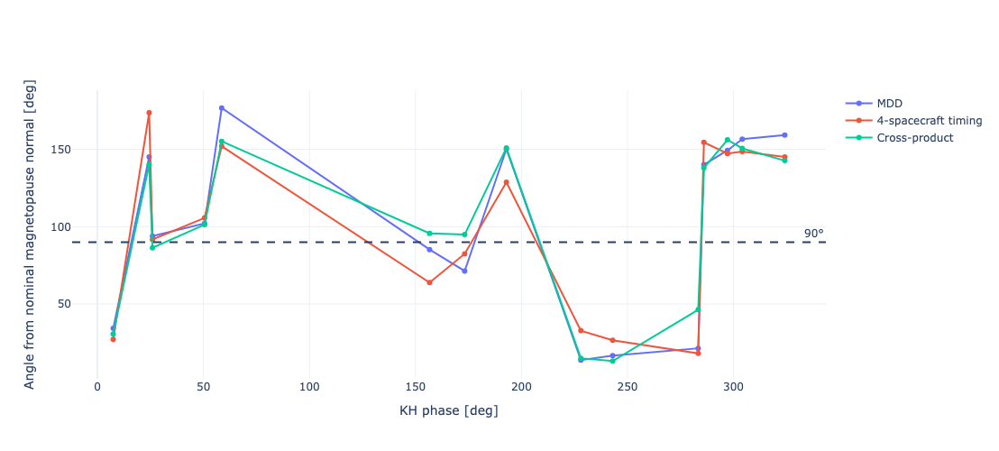

In [58]:
import plotly.graph_objects as go

fig = go.Figure()

fig.add_trace(
    go.Scatter(
        x=rot["KH_phase_deg"],
        y=rot["angle_mdd_mp"],
        mode="lines+markers",
        name="MDD"
    )
)

fig.add_trace(
    go.Scatter(
        x=rot["KH_phase_deg"],
        y=rot["angle_timing_mp"],
        mode="lines+markers",
        name="4-spacecraft timing"
    )
)

fig.add_trace(
    go.Scatter(
        x=rot["KH_phase_deg"],
        y=rot["angle_cross_mp"],
        mode="lines+markers",
        name="Cross-product"
    )
)

# 90-degree overturning threshold
fig.add_hline(
    y=90,
    line_dash="dash",
    annotation_text="90°"
)

fig.update_layout(
    template="plotly_white",
    width=1000,
    height=500,
    xaxis_title="KH phase [deg]",
    yaxis_title="Angle from nominal magnetopause normal [deg]"
)

fig.show()